# Hearing emotion: a speaker-independent audio classification study
## ML-CEP · Part 2

**Question:** can acoustic features distinguish anger, disgust, fear, happiness, neutrality and sadness in actors not used for training?

This notebook follows the assignment's noisy CREMA-D data, low-pass filtering and five required classifiers. It adds explicit speaker separation, controlled ablations, uncertainty estimates and error analysis. All numerical outputs are produced by this project. See `docs/references.md` for sources and attribution.

**Reading guide:** audit → freeze splits → inspect filtering → extract features → select on validation → diagnose → evaluate held-out test → discuss limitations. No test-informed model tuning is permitted.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
assert (ROOT / 'src').exists(), 'Open this notebook from the ML project'
sys.path.insert(0, str(ROOT))
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS']:
    os.environ[key] = '1'
import numpy as np
import pandas as pd
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Audio, Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from threadpoolctl import threadpool_limits
from src.audio_features import SETTINGS, load_audio, lowpass, extract_file
from src.experiments import LABELS, run_selection, run_diagnostics, evaluate_test, candidates
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
print('Python:', sys.version.split()[0], '| Project:', ROOT)
display(pd.Series(SETTINGS.__dict__, name='Audio processing settings'))

Python: 3.12.14 | Project: D:\ML


sample_rate           16000
cutoff_hz              5000
filter_order              4
frame_length            512
hop_length              160
mfcc_count               20
mel_count                40
version         original-v1
Name: Audio processing settings, dtype: object

## 1. Data provenance, audit and split
The specified source is a modified/noisy CREMA-D collection. Filename codes give intended emotions, not crowd-majority perception. We use six emotion classes, not binary sentiment. A raw file hash plus a decoded PCM hash detects exact duplication.

**Split first:** seed 42 assigns 63/14/14 actors to training/validation/test before feature extraction. Actor counts are fixed; clip percentages are approximate. Inspecting validation labels for coverage is not training on validation. Test class counts are shown for integrity only, not used to tune models.

In [2]:
if not (ROOT / 'artifacts/features.npz').exists():
    subprocess.run([sys.executable, str(ROOT / 'scripts/extract_features.py')], cwd=ROOT, check=True)
manifest = pd.read_csv(ROOT / 'data/split_manifest.csv')
audit = pd.read_csv(ROOT / 'reports/data_audit.csv')
display(json.loads((ROOT / 'data/provenance.json').read_text()))
display(audit.groupby('status', dropna=False).size().rename('files').to_frame())
display(audit[audit.status.ne('valid')][['filename', 'issue']])
summary = manifest.groupby('split').agg(clips=('filename','size'), actors=('actor','nunique'),
    duration_min=('duration','min'), duration_max=('duration','max'))
summary['clip_percent'] = 100 * summary.clips / len(manifest)
display(summary.loc[['train','validation','test']])
display(pd.crosstab(manifest.split, manifest.emotion)[LABELS])
display(manifest.groupby(['sample_rate','channels']).size().rename('files').to_frame())
assert not manifest.pcm_sha256.duplicated().any()
assert manifest.groupby('actor').split.nunique().max() == 1
assert manifest.groupby('split').emotion.nunique().eq(6).all()
print('Integrity: no exact decoded-audio duplicates; actors are disjoint; all classes present.')

{'repository': 'https://github.com/naweedfatima03/SentimentAnalysisDataset',
 'commit': '8c764b0b778f90c8b60484afe21715c899d35663',
 'wav_count': 7442,
 'download_method': 'individual immutable blobs; every Git blob SHA-1 verified',
 'total_bytes': 605899936}

,files
status,
excluded,7
valid,7435


,filename,issue
476,1006_TIE_HAP_XX.wav,Identical decoded audio has conflicting emotio...
477,1006_TIE_NEU_XX.wav,Identical decoded audio has conflicting emotio...
1048,1013_WSI_DIS_XX.wav,Identical decoded audio has conflicting emotio...
1052,1013_WSI_SAD_XX.wav,Identical decoded audio has conflicting emotio...
1345,1017_IWW_ANG_XX.wav,Identical decoded audio has conflicting emotio...
1347,1017_IWW_FEA_XX.wav,Identical decoded audio has conflicting emotio...
6187,1076_MTI_SAD_XX.wav,"Short, empty, silent or non-finite audio"


,clips,actors,duration_min,duration_max,clip_percent
split,,,,,
train,5149,63,1.334688,5.005000,69.253531
validation,1146,14,1.368000,4.771438,15.413584
test,1140,14,1.267937,4.804812,15.332885


emotion,anger,disgust,fear,happy,neutral,sad
split,,,,,,
test,195,194,195,195,167,194
train,880,880,880,879,751,879
validation,195,196,195,196,168,196


,,files
sample_rate,channels,
16000.0,1.0,7435


Integrity: no exact decoded-audio duplicates; actors are disjoint; all classes present.


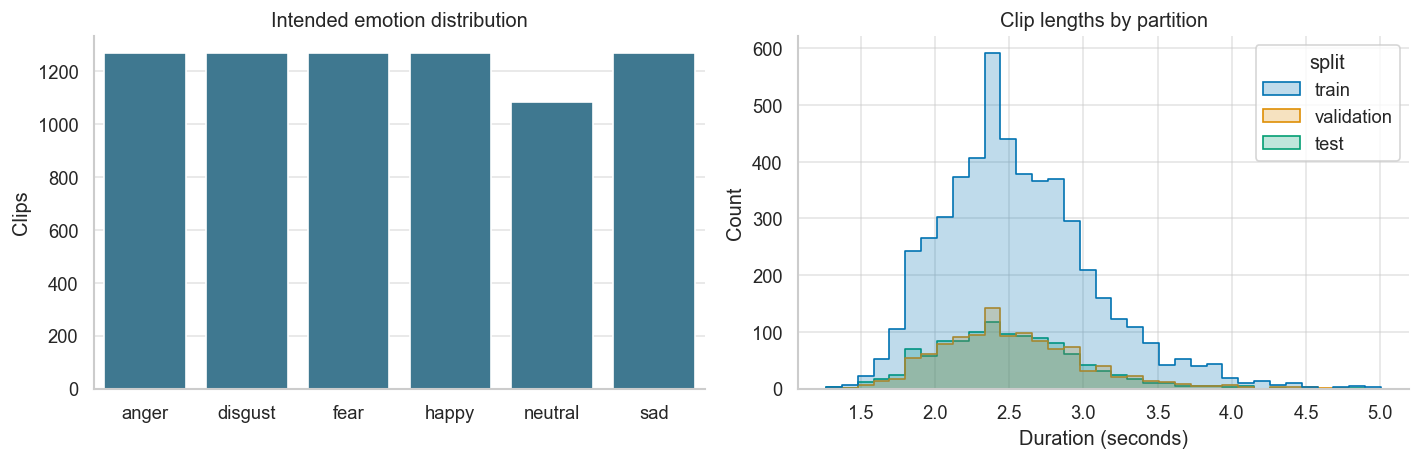

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=manifest, x='emotion', order=LABELS, ax=axes[0], color='#327e9d')
axes[0].set(title='Intended emotion distribution', xlabel='', ylabel='Clips')
sns.histplot(data=manifest, x='duration', hue='split', bins=35, element='step', ax=axes[1])
axes[1].set(title='Clip lengths by partition', xlabel='Duration (seconds)')
fig.tight_layout(); fig.savefig(FIGURES / 'dataset_overview.png', bbox_inches='tight'); plt.show()

## 2. What does the low-pass filter change?
We use 16 kHz mono audio and a fourth-order Butterworth design with 5 kHz cutoff. Forward-backward SOS filtering removes phase delay and squares the single-pass magnitude response. The resulting response is approximately -6 dB at the design cutoff. Playback disables automatic normalization so the comparison does not hide amplitude changes.

High-frequency attenuation is measurable. Improved denoising/SNR cannot be established without a paired clean reference. Listen and compare the spectrum before claiming an improvement.

Training example: **1001_DFA_ANG_XX.wav**, intended emotion **anger**

Original

Filtered

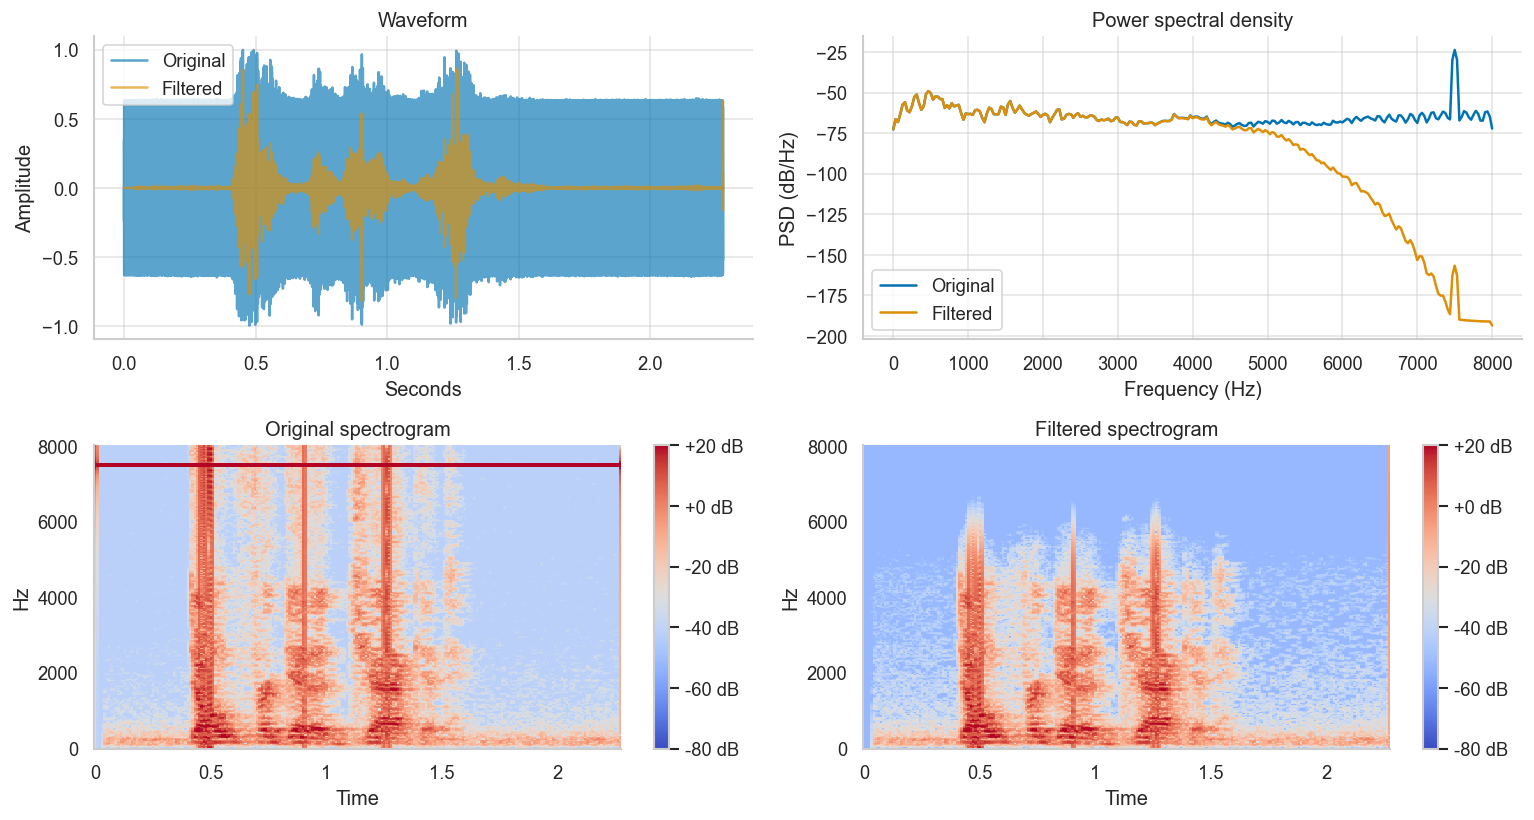

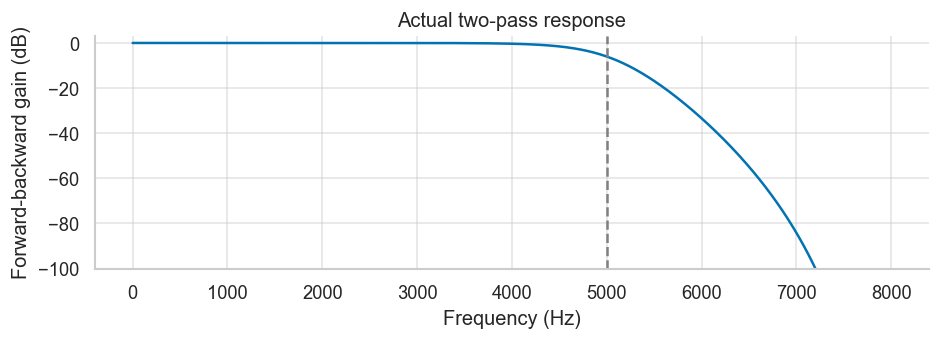

In [4]:
from scipy import signal
import librosa, librosa.display
example = manifest[manifest.split.eq('train')].iloc[0]
original = load_audio(example.path)
filtered = lowpass(original)
display(Markdown(f"Training example: **{example.filename}**, intended emotion **{example.emotion}**"))
display(Markdown('Original')); display(Audio(original, rate=SETTINGS.sample_rate, normalize=False))
display(Markdown('Filtered')); display(Audio(filtered, rate=SETTINGS.sample_rate, normalize=False))
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
time = np.arange(len(original)) / SETTINGS.sample_rate
axes[0,0].plot(time, original, alpha=.65, label='Original')
axes[0,0].plot(time, filtered, alpha=.65, label='Filtered')
axes[0,0].set(xlabel='Seconds', ylabel='Amplitude', title='Waveform'); axes[0,0].legend()
for label, samples in [('Original',original),('Filtered',filtered)]:
    frequencies, power = signal.welch(samples, fs=SETTINGS.sample_rate, nperseg=512)
    axes[0,1].plot(frequencies, 10*np.log10(power+1e-20), label=label)
axes[0,1].set(xlabel='Frequency (Hz)', ylabel='PSD (dB/Hz)', title='Power spectral density'); axes[0,1].legend()
for ax, label, samples in [(axes[1,0],'Original',original),(axes[1,1],'Filtered',filtered)]:
    spectrum = librosa.amplitude_to_db(abs(librosa.stft(samples,n_fft=512,hop_length=160)), ref=1.0)
    image = librosa.display.specshow(spectrum, sr=16000, hop_length=160, x_axis='time', y_axis='linear', ax=ax, vmin=-80, vmax=20)
    ax.set_title(label+' spectrogram'); fig.colorbar(image,ax=ax,format='%+2.0f dB')
fig.tight_layout(); fig.savefig(FIGURES/'filter_example.png',bbox_inches='tight'); plt.show()
sos = signal.butter(4,5000,fs=16000,output='sos')
frequencies,response = signal.sosfreqz(sos,fs=16000,worN=2048)
plt.figure(figsize=(8,3)); plt.plot(frequencies,20*np.log10(np.maximum(abs(response)**2,1e-8)))
plt.axvline(5000,color='grey',linestyle='--'); plt.ylim(-100,3)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Forward-backward gain (dB)'); plt.title('Actual two-pass response')
plt.tight_layout(); plt.savefig(FIGURES/'filter_response.png'); plt.show()

## 3. From a variable-length recording to one feature vector
Feature families: Fourier-band power, MFCCs and deltas, log-Mel, 12-bin chroma, centroid, bandwidth, contrast and bicoherence. RMS, zero-crossing rate, rolloff, flatness and a pitch proxy add context. Frame means/std produce fixed-length vectors. See `docs/methodology.md` for exact settings and literature rationale.

**Bicoherence:** `E[X1 X2 conj(X1+2)] / sqrt(E[|X1 X2|²] E[|X1+2|²])`. We average windowed segments before normalizing; this is not the raw bispectrum. Coarse frequency pairs limit cost. Ordinary wrapped-phase moments are boundary-sensitive and require cautious interpretation.

Per-clip features require no global fitting. In contrast, scaling and LDA learn from data and must stay inside training pipelines. The feature cache includes source and implementation hashes.

In [5]:
bundle = np.load(ROOT / 'artifacts/features.npz')
features = bundle['filtered']; feature_names = bundle['names'].astype(str)
assert np.array_equal(bundle['filenames'], manifest.filename.to_numpy())
assert np.isfinite(features).all() and np.isfinite(bundle['unfiltered']).all()
display(pd.Series(feature_names).str.extract(r'^([a-z]+)')[0].value_counts().rename('columns').to_frame())
print('Filtered matrix:', features.shape, '| Unfiltered matrix:', bundle['unfiltered'].shape)
display(pd.DataFrame({'feature': feature_names, 'first_training_clip': features[manifest.split.eq('train')][0]}).head(12))

,columns
0,
mfcc,120
mel,80
chroma,24
spectral,20
fourier,14
bicoherence,8
pitch,3
rms,2
zcr,2


Filtered matrix: (7435, 273) | Unfiltered matrix: (7435, 273)


,feature,first_training_clip
0,mfcc_00_mean,-260.549035
1,mfcc_01_mean,73.969086
2,mfcc_02_mean,-8.875510
3,mfcc_03_mean,32.340551
4,mfcc_04_mean,-5.280400
5,mfcc_05_mean,8.971422
6,mfcc_06_mean,-10.372677
7,mfcc_07_mean,0.827660
8,mfcc_08_mean,-1.102346
9,mfcc_09_mean,-4.913170


## 4. Five classifiers, one validation policy
KNN uses local distances; logistic regression learns linear log-odds; GaussianNB assumes class-conditional independent Gaussian features; RBF SVM builds nonlinear margins; MLP learns nonlinear hidden representations. Each is evaluated with training-only scaling, with and without supervised LDA.

We choose within each family by **validation macro-F1**, then accuracy, then predeclared candidate order. The overall winner is selected using the same rule. Macro-F1 gives equal weight to each emotion. Distance-weighted KNN often predicts its own training points perfectly, so training scores are not generalization estimates. A dedicated validation partition remains separate; MLP internal random validation is disabled.

### Readable training implementation
The following cells contain this project's actual candidate definitions and training/validation loop, synchronized from our reusable module when the notebook is built. They are executable code, not screenshots. Checkpoints let a completed full search be reopened without retraining; source/data fingerprints prevent stale reuse. Every pipeline fits training data only.

For SVM, `TrainingRBFKernel` computes the ordinary RBF Gram matrix against training references and supplies it to SVC's precomputed interface. This keeps the same kernel, gamma/C grid and train-only fitting while avoiding repeated scalar distance calculations. Equivalence tests compare it against standard RBF SVC; see the methodology for details.

In [6]:
import time, warnings, joblib
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from src.experiments import score_predictions, experiment_identity, load_inputs, save_artifact
from src.rbf_kernel import TrainingRBFKernel

In [7]:
def candidates():
    """Yield 76 predeclared pipelines in a deterministic tie-break order."""
    definitions = {
        "KNN": (
            KNeighborsClassifier(n_jobs=1),
            {"n_neighbors": [3, 5, 9, 15, 21], "weights": ["uniform", "distance"]},
        ),
        "Logistic Regression": (
            LogisticRegression(max_iter=2000, random_state=42),
            {"C": [0.01, 0.1, 1, 10]},
        ),
        "GaussianNB": (GaussianNB(), {"var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5]}),
        "SVM": (
            SVC(kernel="rbf"),
            {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.001, 0.01]},
        ),
        "MLP": (
            MLPClassifier(max_iter=500, early_stopping=False, random_state=42),
            {
                "hidden_layer_sizes": [(128,), (128, 64)],
                "alpha": [0.0001, 0.001],
                "learning_rate_init": [0.0003, 0.001],
            },
        ),
    }
    for family, (estimator, grid) in definitions.items():
        # Predeclared simplicity order for exact metric ties: no LDA first,
        # then ParameterGrid's deterministic order, never test performance.
        for reduction in [False, True]:
            for parameters in ParameterGrid(grid):
                steps = [("scale", StandardScaler())]
                if reduction:
                    steps.append(("lda", LinearDiscriminantAnalysis()))
                if family == "SVM":
                    steps.append(
                        ("kernel", TrainingRBFKernel(gamma=parameters["gamma"]))
                    )
                    classifier = SVC(kernel="precomputed", C=parameters["C"])
                else:
                    classifier = clone(estimator).set_params(**parameters)
                steps.append(("classifier", classifier))
                yield family, reduction, parameters, Pipeline(steps)

In [8]:
def run_selection(root):
    """Fit on training actors, rank on validation actors, then freeze winners."""
    root = Path(root)
    manifest, features = load_inputs(root)
    identity = experiment_identity(root)
    checkpoint = root / "artifacts/selection_checkpoint.joblib"
    state = (
        joblib.load(checkpoint)
        if checkpoint.exists()
        else {"identity": identity, "rows": [], "best": {}}
    )
    if state["identity"] != identity:
        raise ValueError(
            "Selection checkpoint is stale: archive old outputs before rerunning"
        )
    x = features["filtered"]
    y = manifest.emotion.to_numpy()
    train = manifest.split.eq("train").to_numpy()
    valid = manifest.split.eq("validation").to_numpy()
    with threadpool_limits(limits=1):
        for order, (family, reduction, parameters, pipeline) in enumerate(candidates()):
            if order < len(state["rows"]):
                continue
            started = time.perf_counter()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                pipeline.fit(x[train], y[train])
            train_scores = score_predictions(y[train], pipeline.predict(x[train]))
            valid_predictions = pipeline.predict(x[valid])
            valid_scores = score_predictions(y[valid], valid_predictions)
            row = {
                "candidate": order,
                "model": family,
                "lda": reduction,
                "parameters": json.dumps(parameters),
                "seconds": time.perf_counter() - started,
                "warnings": " | ".join(str(w.message) for w in caught),
                **{"train_" + k: v for k, v in train_scores.items()},
                **{"validation_" + k: v for k, v in valid_scores.items()},
            }
            state["rows"].append(row)
            rank = (valid_scores["macro_f1"], valid_scores["accuracy"], -order)
            if family not in state["best"] or rank > state["best"][family]["rank"]:
                state["best"][family] = {
                    "rank": rank,
                    "pipeline": pipeline,
                    "row": row,
                    "validation_predictions": valid_predictions,
                }
            save_artifact(state, checkpoint)
            pd.DataFrame(state["rows"]).to_csv(
                root / "reports/search_results.csv", index=False
            )
            print(
                f"{order + 1}/76 {family} lda={reduction}: validation F1={valid_scores['macro_f1']:.4f}, {row['seconds']:.1f}s",
                flush=True,
            )
    champion_name = max(state["best"], key=lambda name: state["best"][name]["rank"])
    frozen = {
        "identity": identity,
        "selection_metric": "validation macro-F1, accuracy, candidate order",
        "winner": champion_name,
        "models": {name: item["row"] for name, item in state["best"].items()},
    }
    (root / "artifacts/frozen_selection.json").write_text(json.dumps(frozen, indent=2))
    save_artifact(state["best"], root / "artifacts/selected_models.joblib")
    save_artifact(
        state["best"][champion_name]["pipeline"],
        root / "artifacts/winning_pipeline.joblib",
    )
    pd.DataFrame([item["row"] for item in state["best"].values()]).to_csv(
        root / "reports/validation_results.csv", index=False
    )
    return frozen

In [9]:
candidate_summary = []
from src.experiments import candidates as reusable_candidates
notebook_specs = [(name, lda, parameters) for name, lda, parameters, _ in candidates()]
source_specs = [(name, lda, parameters) for name, lda, parameters, _ in reusable_candidates()]
assert notebook_specs == source_specs, 'Edit src/experiments.py and rebuild the notebook before changing the search'
for family, lda, parameters, pipeline in candidates():
    candidate_summary.append({'model': family, 'LDA': lda, 'parameters': str(parameters)})
display(pd.DataFrame(candidate_summary).groupby(['model','LDA']).size().rename('candidates').to_frame())
print('Total candidates:', len(candidate_summary))
frozen = run_selection(ROOT)
search = pd.read_csv(ROOT / 'reports/search_results.csv')
validation = pd.read_csv(ROOT / 'reports/validation_results.csv')
display(validation[['model','lda','parameters','train_macro_f1','validation_macro_f1','validation_accuracy','seconds','warnings']])
print('Validation-selected winner:', frozen['winner'])
print('Candidates with recorded warnings:', search.warnings.fillna('').ne('').sum())

candidates
model               LDA              
GaussianNB          False           4
                    True            4
KNN                 False          10
                    True           10
Logistic Regression False           4
                    True            4
MLP                 False           8
                    True            8
SVM                 False          12
                    True           12

Total candidates: 76


,model,lda,parameters,train_macro_f1,validation_macro_f1,validation_accuracy,seconds,warnings
0,KNN,True,"{""n_neighbors"": 15, ""weights"": ""uniform""}",0.669766,0.489272,0.493892,1.770968,NaN
1,Logistic Regression,True,"{""C"": 0.01}",0.648760,0.496885,0.500873,0.821637,NaN
2,GaussianNB,True,"{""var_smoothing"": 1e-11}",0.638527,0.478758,0.486038,0.716299,NaN
3,SVM,False,"{""C"": 100, ""gamma"": 0.001}",0.977149,0.498265,0.501745,6.866973,NaN
4,MLP,True,"{""alpha"": 0.001, ""hidden_layer_sizes"": [128], ...",0.661799,0.493485,0.498255,16.658407,Stochastic Optimizer: Maximum iterations (500)...


Validation-selected winner: SVM
Candidates with recorded warnings: 7


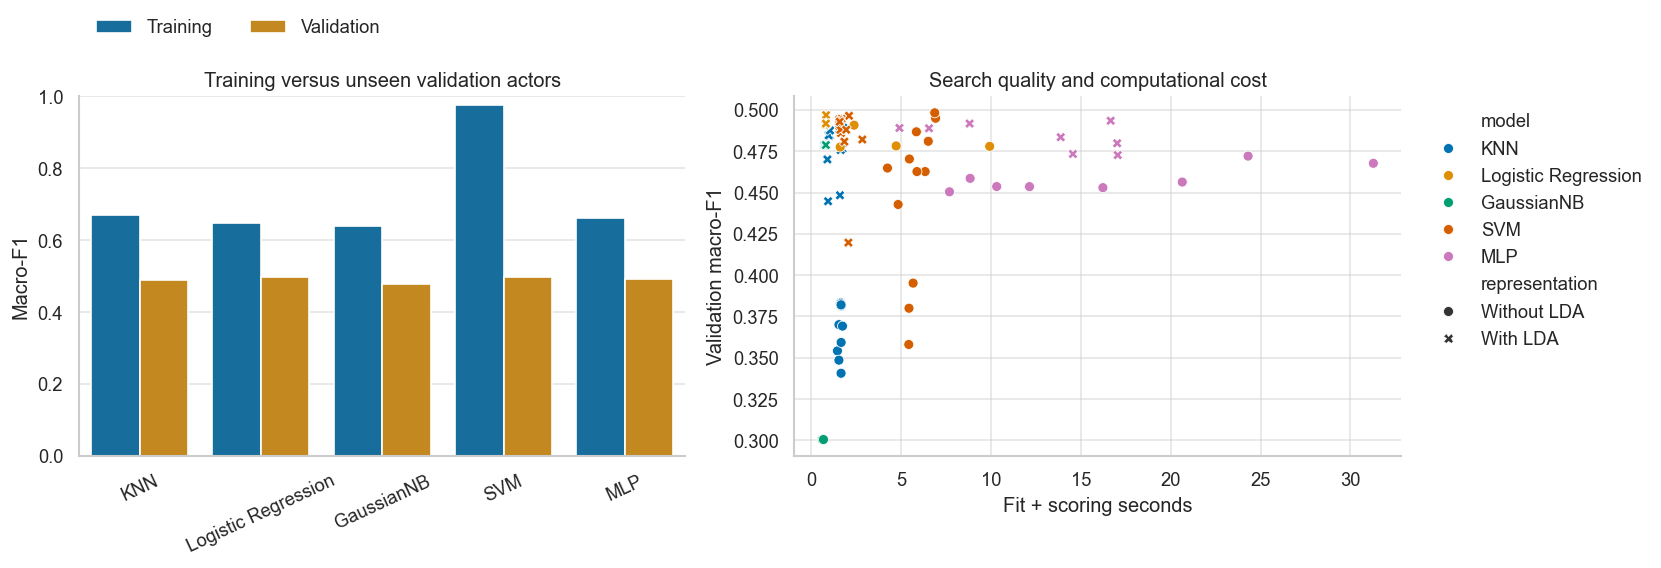

In [10]:
fig, axes = plt.subplots(1,2,figsize=(14,5))
chart = validation.melt(id_vars='model', value_vars=['train_macro_f1','validation_macro_f1'],var_name='partition',value_name='macro_f1')
chart['partition'] = chart.partition.map({'train_macro_f1':'Training','validation_macro_f1':'Validation'})
sns.barplot(data=chart,x='model',y='macro_f1',hue='partition',ax=axes[0]); axes[0].set_ylim(0,1)
axes[0].tick_params(axis='x',rotation=25); axes[0].set_title('Training versus unseen validation actors')
axes[0].set(xlabel='',ylabel='Macro-F1')
axes[0].legend(title=None,loc='lower left',bbox_to_anchor=(0,1.12),ncol=2,frameon=False)
search_plot = search.assign(representation=np.where(search.lda,'With LDA','Without LDA'))
sns.scatterplot(data=search_plot,x='seconds',y='validation_macro_f1',hue='model',style='representation',ax=axes[1])
axes[1].set(xlabel='Fit + scoring seconds',ylabel='Validation macro-F1',title='Search quality and computational cost')
axes[1].legend(loc='upper left',bbox_to_anchor=(1.02,1),frameon=False)
fig.tight_layout(); fig.savefig(FIGURES/'validation_comparison.png',bbox_inches='tight'); plt.show()

## 5. Controlled diagnostics on validation data
The ablation holds SVM settings fixed at C=1, gamma=scale and uses no LDA. This isolates the representation more fairly than comparing separately tuned models. The filtered combined representation stays predeclared for final models; these diagnostics do not trigger a test-informed redesign.

The learning curve uses nested actor subsets and unchanged validation actors. It is conditional on the validation-selected configuration, so it is not an independent estimate of model-selection performance.

D:\ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,experiment,feature_count,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,unfiltered_full,273,0.475567,0.464337,0.464401,0.477108
1,filtered_mfcc,120,0.446771,0.433704,0.434755,0.446187
2,filtered_spectral,34,0.413613,0.401484,0.401232,0.414946
3,filtered_combined,273,0.481675,0.470304,0.470305,0.484199


,actors,clips,train_macro_f1,validation_macro_f1,warnings
0,16,1308,0.996952,0.431111,NaN
1,32,2620,0.989817,0.458749,NaN
2,47,3838,0.985238,0.496653,NaN
3,63,5149,0.977149,0.498265,NaN


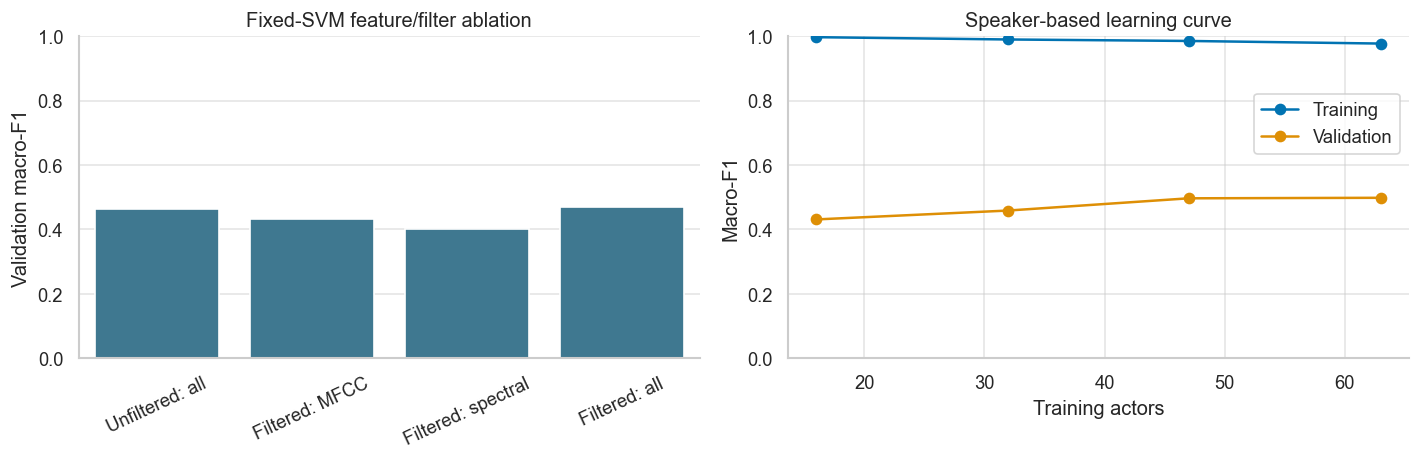

In [11]:
ablation = run_diagnostics(ROOT)
learning = pd.read_csv(ROOT / 'reports/learning_curve.csv')
display(ablation); display(learning)
fig, axes = plt.subplots(1,2,figsize=(12,4))
ablation_plot = ablation.assign(description=ablation.experiment.map({'unfiltered_full':'Unfiltered: all','filtered_mfcc':'Filtered: MFCC','filtered_spectral':'Filtered: spectral','filtered_combined':'Filtered: all'}))
sns.barplot(data=ablation_plot,x='description',y='macro_f1',ax=axes[0],color='#327e9d')
axes[0].tick_params(axis='x',rotation=25); axes[0].set(title='Fixed-SVM feature/filter ablation',ylim=(0,1),ylabel='Validation macro-F1',xlabel='')
axes[1].plot(learning.actors,learning.train_macro_f1,'o-',label='Training')
axes[1].plot(learning.actors,learning.validation_macro_f1,'o-',label='Validation')
axes[1].set(xlabel='Training actors',ylabel='Macro-F1',ylim=(0,1),title='Speaker-based learning curve'); axes[1].legend(loc='upper right',bbox_to_anchor=(1,.85))
fig.tight_layout(); fig.savefig(FIGURES/'diagnostic_experiments.png',bbox_inches='tight'); plt.show()

## 6. Where does the validation winner struggle?
Inspect off-diagonal confusions and listen to representative validation errors. Acoustic explanations are hypotheses, not measured causes. Intended labels may differ from perceived emotion. Intensity and duration subgroup scores require their sample sizes; a small subgroup should not drive a broad claim. Subgroup macro-F1 uses the fixed six labels, so absent classes contribute zero; different intensity groups may have different class coverage and are not directly comparable. Balanced accuracy averages recalls over classes present in each subgroup.

In [12]:
validation_predictions = pd.read_csv(ROOT / 'reports/validation_predictions.csv')
mistakes = validation_predictions[~validation_predictions.correct]
confusions = mistakes.groupby(['emotion','prediction']).size().sort_values(ascending=False).rename('clips').reset_index()
display(confusions.head(10))
display(pd.read_csv(ROOT / 'reports/validation_by_intensity.csv'))
display(pd.read_csv(ROOT / 'reports/validation_by_duration_bin.csv'))
for pair in confusions.head(2).itertuples():
    row = mistakes[(mistakes.emotion==pair.emotion)&(mistakes.prediction==pair.prediction)].iloc[0]
    display(Markdown(f"**{row.filename}:** intended {row.emotion}, predicted {row.prediction}; duration {row.duration:.2f}s, intensity {row.intensity}. Listen for energy, pitch and voice quality; these alone do not establish why the model erred."))
    display(Audio(load_audio(row.path),rate=16000,normalize=False))

,emotion,prediction,clips
0,happy,anger,42
1,fear,anger,37
2,disgust,anger,33
3,fear,sad,30
4,sad,neutral,29
5,neutral,disgust,26
6,fear,happy,25
7,anger,disgust,25
8,happy,neutral,25
9,neutral,happy,23


,intensity,clips,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,HI,70,0.585714,0.499118,0.598942,0.585714
1,LO,70,0.485714,0.413628,0.496353,0.485714
2,MD,70,0.500000,0.443843,0.532612,0.500000
3,XX,936,0.496795,0.493610,0.493639,0.496955


,duration_bin,clips,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,"[0.0, 2.0)",126,0.468254,0.432166,0.460609,0.431685
1,"[2.0, 3.0)",848,0.485849,0.480453,0.481507,0.485293
2,"[3.0, 4.0)",160,0.625000,0.589914,0.615211,0.586469
3,"[4.0, inf)",12,0.333333,0.188034,0.341880,0.200000


**1017_WSI_HAP_XX.wav:** intended happy, predicted anger; duration 1.57s, intensity XX. Listen for energy, pitch and voice quality; these alone do not establish why the model erred.

**1031_IEO_FEA_HI.wav:** intended fear, predicted anger; duration 1.77s, intensity HI. Listen for energy, pitch and voice quality; these alone do not establish why the model erred.

## 7. Frozen models meet the held-out actors
Selection metadata has already been written. No hyperparameters, feature choices or fitted preprocessing are changed here. All models remain fitted on training actors only. The majority-class baseline helps judge whether the models learn beyond class frequencies.

The reported champion remains the validation-selected model, regardless of which test row happens to be largest. Cluster bootstrap intervals resample complete test actors 1,000 times; they do not include training randomness or selection uncertainty.

,model,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,Majority baseline,0.171053,0.048689,0.049970,0.166667
1,KNN,0.538596,0.535492,0.536319,0.536962
2,Logistic Regression,0.541228,0.538973,0.540036,0.539535
3,GaussianNB,0.547368,0.544641,0.545236,0.546578
4,SVM,0.552632,0.549660,0.550435,0.550620
5,MLP,0.556140,0.552323,0.553093,0.554821


{'winner': 'SVM',
 'resamples': 1000,
 'unit': 'test actor',
 'accuracy': [0.5043346991009593, 0.6021484515228798],
 'macro_f1': [0.4988353267253136, 0.5990671607492496]}

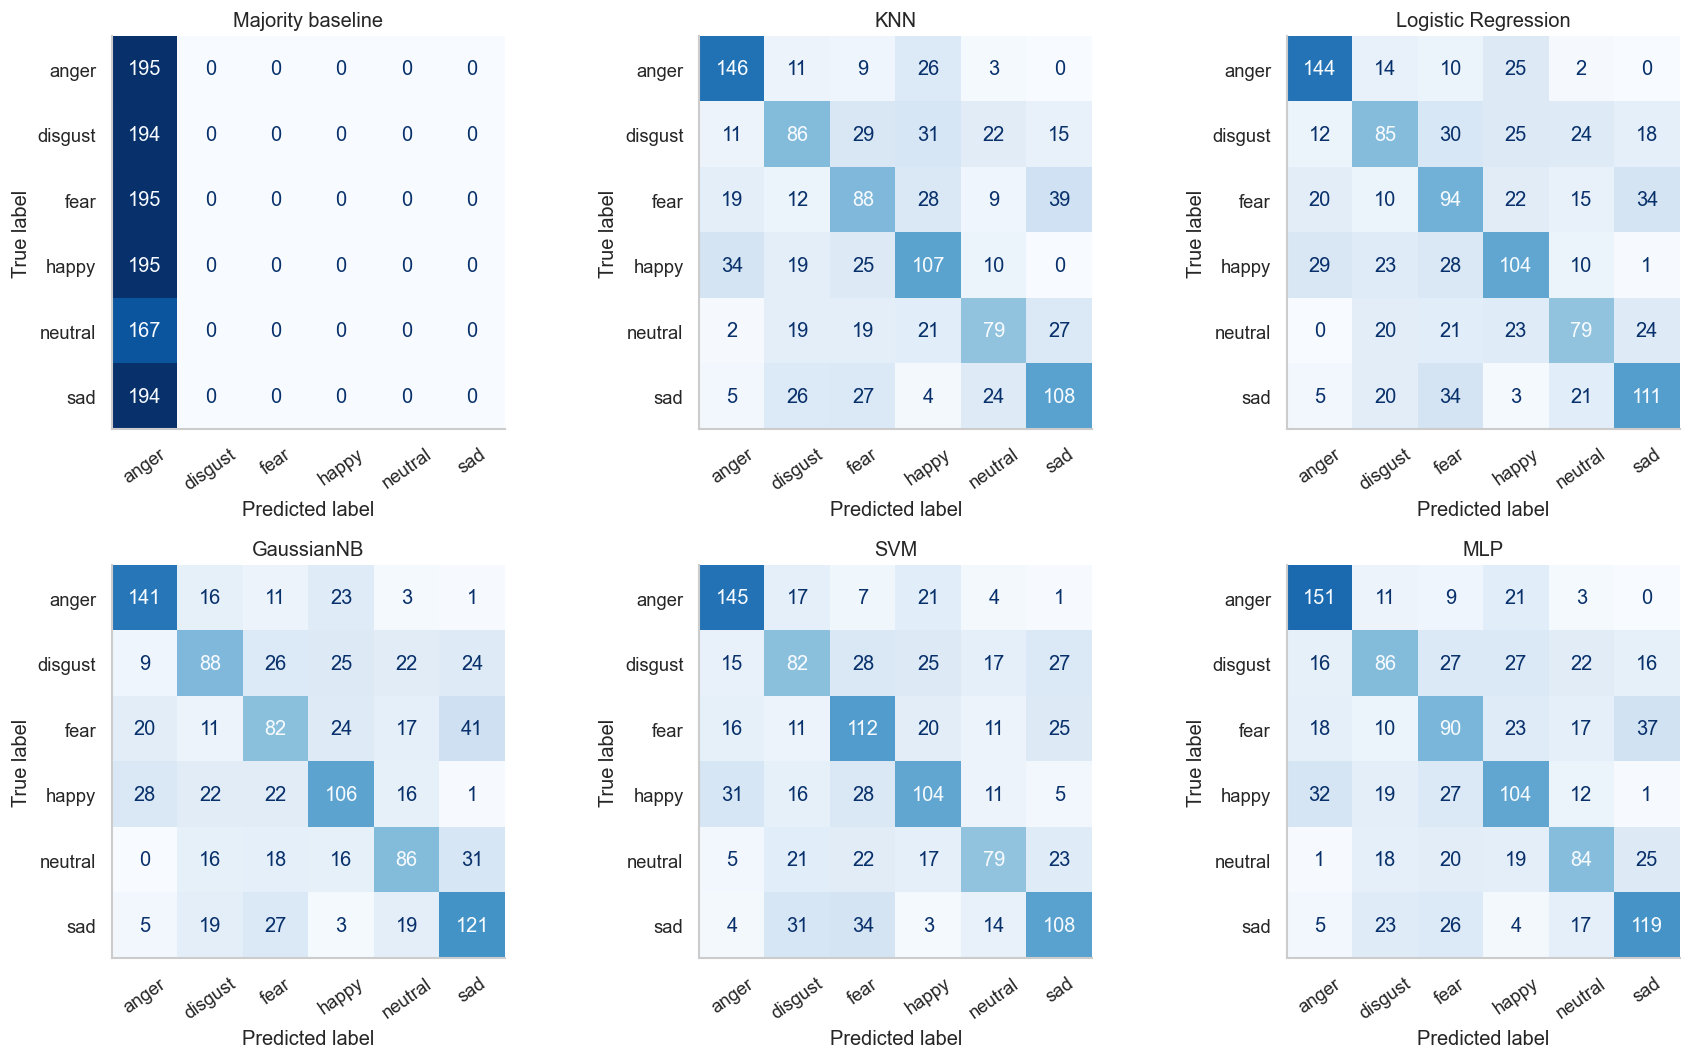

,precision,recall,f1-score,support
anger,0.671296,0.743590,0.705596,195.000000
disgust,0.460674,0.422680,0.440860,194.000000
fear,0.484848,0.574359,0.525822,195.000000
happy,0.547368,0.533333,0.540260,195.000000
neutral,0.580882,0.473054,0.521452,167.000000
sad,0.571429,0.556701,0.563969,194.000000
accuracy,0.552632,0.552632,0.552632,0.552632
macro avg,0.552750,0.550620,0.549660,1140.000000
weighted avg,0.552123,0.552632,0.550435,1140.000000


Validation-selected **SVM** obtained test accuracy **0.553** and macro-F1 **0.550**. Actor-bootstrap 95% intervals: accuracy **0.504–0.602**, macro-F1 **0.499–0.599**.

In [13]:
test_results = evaluate_test(ROOT)
display(test_results)
intervals = json.loads((ROOT/'reports/bootstrap_intervals.json').read_text())
display(intervals)
test_predictions = pd.read_csv(ROOT/'reports/test_predictions.csv')
fig, axes = plt.subplots(2,3,figsize=(15,9))
for ax, name in zip(axes.ravel(),test_results.model):
    matrix = confusion_matrix(test_predictions.emotion,test_predictions[name],labels=LABELS)
    ConfusionMatrixDisplay(matrix,display_labels=LABELS).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d',im_kw={'vmin':0,'vmax':int(test_predictions.emotion.value_counts().max())})
    ax.grid(False)
    ax.set_title(name); ax.tick_params(axis='x',rotation=35)
fig.tight_layout(); fig.savefig(FIGURES/'test_confusion_matrices.png',bbox_inches='tight'); plt.show()
winner = frozen['winner']
classification = json.loads((ROOT/'reports'/f'classification_{winner.replace(" ","_")}.json').read_text())
display(pd.DataFrame(classification).T)
chosen = test_results[test_results.model.eq(winner)].iloc[0]
display(Markdown(f"Validation-selected **{winner}** obtained test accuracy **{chosen.accuracy:.3f}** and macro-F1 **{chosen.macro_f1:.3f}**. Actor-bootstrap 95% intervals: accuracy **{intervals['accuracy'][0]:.3f}–{intervals['accuracy'][1]:.3f}**, macro-F1 **{intervals['macro_f1'][0]:.3f}–{intervals['macro_f1'][1]:.3f}**."))

## 8. Reusable prediction and verification
The saved pipeline contains the scaler, optional LDA and classifier. `predict_emotion` extracts the same filtered feature schema used during training. A prediction on a known held-out example should exactly match the recorded test-stage result. This interface is an offline demonstration, not evidence of accuracy on arbitrary microphones or languages.

In [14]:
from src.inference import predict_emotion
prediction_example = test_predictions.iloc[0]
predicted_emotion = predict_emotion(prediction_example.path, ROOT)
assert predicted_emotion == prediction_example[winner]
print('File:', prediction_example.filename, '| Intended:', prediction_example.emotion, '| Predicted:', predicted_emotion)
import joblib
training_rows = manifest.split.eq('train').to_numpy()
for item in joblib.load(ROOT/'artifacts/selected_models.joblib').values():
    scaler = item['pipeline'].named_steps['scale']
    np.testing.assert_allclose(scaler.mean_, features[training_rows].mean(axis=0))
    assert scaler.n_samples_seen_ == training_rows.sum()
print('Verified training-only scaling and saved-model consistency.')

File: 1009_DFA_ANG_XX.wav | Intended: anger | Predicted: happy
Verified training-only scaling and saved-model consistency.


## 9. Interpretation and limitations
The final report is generated from these saved experiment tables, not hand-entered scores. Speaker separation is stricter than random clip splitting, so this study must not compare accuracy directly against a project with a different split or data leakage.

Acted emotions, shared sentences, one dataset and intended-emotion labels limit real-world generalization. Clip summaries lose temporal structure; correlated feature families can challenge Naive Bayes; LDA assumes restrictive class structure; MLP convergence and validation selection variability remain limitations. Bicoherence estimates are coarse and phase moments are boundary-sensitive. Pitch is a proxy, not a clinical measurement. Fourteen test actors provide limited population coverage.

Future work should use another corpus and multiple grouped splits or nested grouped validation, followed by an untouched external test set. Repeated test-driven tuning would invalidate the present estimate. No high accuracy is promised or fabricated.

See `docs/methodology.md`, `docs/references.md`, `docs/viva_notes.md`, `docs/requirements_checklist.md`, and `reports/final_report.md` for detailed supporting material.